| BERT BASE |
Métricas medidas com SPAN com 10 épocas e 30 experimentos no Collab.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
caminho = '/content/drive/MyDrive/Colab Notebooks'
os.chdir(caminho)

In [3]:
# Update e instalação dos pacotes e dependências usados

!pip install -q transformers datasets evaluate seqeval accelerate

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 4.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 7.6 MB/s eta 0:00:00


In [4]:
# Importações necessárias

import os
import gc
import shutil
import csv
import re
from typing import List, Tuple, Dict, Optional

import pandas as pd
import torch
import numpy as np
import matplotlib.pyplot as plt

from datasets import Dataset, DatasetDict, concatenate_datasets, disable_caching
from transformers import (
    AutoTokenizer,
    AutoModelForTokenClassification,
    TrainingArguments,
    Trainer,
    DataCollatorForTokenClassification,
    EarlyStoppingCallback
)
from transformers import logging as hf_logging
import evaluate


disable_caching()
hf_logging.set_verbosity_error()

metric = evaluate.load("seqeval")

In [5]:
import torch
device = torch.device('cuda')
print(f"Usando dispositivo: {device}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"CUDA version: {torch.version.cuda}")

Usando dispositivo: cuda
PyTorch version: 2.11.0+cu128
CUDA available: True
CUDA version: 12.8


In [6]:
# Definição dos rótulos BIO
lista_rotulos = ["O", "B-WRONG", "I-WRONG"]
label_to_id = {label: i for i, label in enumerate(lista_rotulos)}
id_to_label = {i: label for i, label in enumerate(lista_rotulos)}

In [7]:
# Métricas a nível de Span

def compute_metrics(p):
    predictions, labels = p
    predictions = np.argmax(predictions, axis=2)

    # Remove os índices de ignorados (-100) e converte para labels de texto
    true_predictions = [
        [id_to_label[p] for (p, l) in zip(prediction, label) if l != -100]
        for prediction, label in zip(predictions, labels)
    ]
    true_labels = [
        [id_to_label[l] for (p, l) in zip(prediction, label) if l != -100]
        for prediction, label in zip(predictions, labels)
    ]

    results = metric.compute(predictions=true_predictions, references=true_labels)

    precision = results["overall_precision"]
    recall = results["overall_recall"]

    # F0.5 Score
    if precision + recall == 0: # Para evitar divisões por 0
        f0_5=0.0

    else:
        f0_5= (1+0.5**2) * (precision*recall) / ((0.5**2 * precision) + recall)

    return {
        "precision": precision,
        "recall": recall,
        "f0_5": f0_5,
        "accuracy": results["overall_accuracy"],
    }

In [8]:
# Lê arquivo CONLL (TSV)

def ler_conll(
    path: str,
    *,
    ignore_header_regex: str = r"^\s*Sentença\s+Original\s+N[°º]\s*\d+",
    allow_space_in_token: bool = False,
    strict_two_columns: bool = False,
    verbose: bool = True,
) -> Tuple[List[List[str]], List[List[str]]]:
    header_pat = re.compile(ignore_header_regex, flags=re.IGNORECASE)
    tokens_per_sent, tags_per_sent = [], []
    cur_tokens, cur_tags = [], []

    def flush_sentence():
        nonlocal cur_tokens, cur_tags
        if cur_tokens:
            tokens_per_sent.append(cur_tokens)
            tags_per_sent.append(cur_tags)
        cur_tokens, cur_tags = [], []

    with open(path, "r", encoding="utf-8") as f:
        for lineno, raw in enumerate(f, start=1):
            line = raw.rstrip("\n")

            # Ignora linhas de cabeçalho por sentença
            if header_pat.search(line):
                flush_sentence()
                continue

            # Delimitador de sentença
            if line.strip() == "":
                flush_sentence()
                continue

            # Tenta split por TAB primeiro, senão por espaço
            if "\t" in line:
                parts = line.split("\t")
            else:
                # Divide por qualquer espaço
                parts = line.strip().split()

            if strict_two_columns:
                if len(parts) != 2:
                    if verbose:
                        print(f"[AVISO] Linha {lineno} ignorada (esperado 2 colunas): {line}")
                    continue
                token, tag = parts[0], parts[1]
            else:
                if len(parts) < 2:
                    if verbose:
                        print(f"[AVISO] Linha {lineno} ignorada (colunas insuficientes): {line}")
                    continue
                if allow_space_in_token:
                    # Última coluna é tag; o resto é token (pode conter espaços/tabs)
                    *token_parts, tag = parts
                    token = " ".join(token_parts)
                else:
                    # Primeira é token, última é tag (se houver colunas no meio, descartamos/avisamos)
                    token, tag = parts[0], parts[-1]
                    if len(parts) > 2 and verbose:
                        print(f"[OBSERVAÇÃO] Linha {lineno} possuía colunas extras; usando 1ª como token e última como tag.")

            # Sanidade básica da tag
            if not tag or tag.isspace():
                if verbose:
                    print(f"[AVISO] Linha {lineno} com tag vazia; ignorada: {line}")
                continue

            cur_tokens.append(token)
            cur_tags.append(tag)

    # Última sentença (se não terminar com linha em branco)
    flush_sentence()

    return tokens_per_sent, tags_per_sent

In [9]:
def make_hf_dataset_from_tokens(tokens_per_sent, tags_per_sent, label2id):
    O_ID = label2id.get("O", 0)
    encoded_tags = [[label2id.get(tag, O_ID) for tag in tags] for tags in tags_per_sent]
    return Dataset.from_dict({"tokens": tokens_per_sent, "ner_tags": encoded_tags})

In [10]:
# Carregamento do Dataset já com os labels BIO
path_treino = "train_bio.tsv"
path_teste = "test_bio.tsv"
path_validacao = "val_bio.tsv"

tokens_tr, tags_tr = ler_conll(path_treino, verbose=False)
tokens_ts, tags_ts = ler_conll(path_teste, verbose=False)
tokens_va, tags_va = ler_conll(path_validacao, verbose=False)

ds_tr = make_hf_dataset_from_tokens(tokens_tr, tags_tr, label_to_id)
ds_ts = make_hf_dataset_from_tokens(tokens_ts, tags_ts, label_to_id)
ds_va = make_hf_dataset_from_tokens(tokens_va, tags_va, label_to_id)

full_dataset = concatenate_datasets([ds_tr, ds_ts, ds_va])

# Tokenização e alinhamento único
tokenizer = AutoTokenizer.from_pretrained("neuralmind/bert-base-portuguese-cased")

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [11]:
# Função para equiparar lista de labels com lista de tokens

def tokenize_and_align_labels(batch, tokenizer, label_all_subtokens: bool = False):
    tokenized = tokenizer(
        batch["tokens"],
        truncation=True,
        padding=False,
        is_split_into_words=True,
    )

    all_labels = []
    for i, word_labels in enumerate(batch["ner_tags"]):
        # Mapeia o subtoken com a palavra original
        word_ids = tokenized.word_ids(batch_index=i)
        previous_word_id = None
        label_ids = []

        for word_id in word_ids:
            if word_id is None:
                # Caractere especial é ignorado
                label_ids.append(-100)
            elif word_id != previous_word_id:
                # Primeiro pedaço da palavra recebe tag original
                label_ids.append(word_labels[word_id])
            else:
                # Sub-token da mesma palavra (word) é alinhado à label original
                label_ids.append(word_labels[word_id] if label_all_subtokens else -100)
            previous_word_id = word_id

        all_labels.append(label_ids)

    tokenized["labels"] = all_labels
    return tokenized

print("Tokenizando o dataset unificado uma única vez...")
full_tokenized_dataset = full_dataset.map(
    tokenize_and_align_labels,
    batched=True,
    remove_columns=full_dataset.column_names,
    fn_kwargs={"tokenizer": tokenizer}
)

data_collator = DataCollatorForTokenClassification(tokenizer=tokenizer, padding=True)


Tokenizando o dataset unificado uma única vez...


Map:   0%|          | 0/19250 [00:00<?, ? examples/s]

🔄 Arquivo parcial de resultados encontrado! Carregando progresso anterior...
Retomando a partir da rodada 27...
🔄 Arquivo parcial de losses encontrado! Carregando histórico de curvas...


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

...

{'loss': '1.17', 'grad_norm': '1.253', 'learning_rate': '1.8e-05', 'epoch': '1'}
{'loss': '0.9562', 'grad_norm': '2.737', 'learning_rate': '1.6e-05', 'epoch': '2'}
{'loss': '0.7585', 'grad_norm': '3.06', 'learning_rate': '1.4e-05', 'epoch': '3'}
{'loss': '0.5731', 'grad_norm': '5.466', 'learning_rate': '1.2e-05', 'epoch': '4'}
{'loss': '0.4399', 'grad_norm': '8.456', 'learning_rate': '1e-05', 'epoch': '5'}
{'loss': '0.3578', 'grad_norm': '9.433', 'learning_rate': '8.002e-06', 'epoch': '6'}
{'loss': '0.2921', 'grad_norm': '12.68', 'learning_rate': '6.002e-06', 'epoch': '7'}
{'loss': '0.2481', 'grad_norm': '4.066', 'learning_rate': '4.002e-06', 'epoch': '8'}
{'loss': '0.2126', 'grad_norm': '3.06', 'learning_rate': '2.002e-06', 'epoch': '9'}
{'loss': '0.1904', 'grad_norm': '1.164', 'learning_rate': '2.077e-09', 'epoch': '10'}
{'train_runtime': '1851', 'train_samples_per_second': '83.19', 'train_steps_per_second': '5.202', 'train_loss': '0.5198', 'epoch': '10'}
{'eval_loss': '0.5002', 'eva

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.154', 'grad_norm': '1.992', 'learning_rate': '1.8e-05', 'epoch': '1'}
{'loss': '0.9455', 'grad_norm': '1.867', 'learning_rate': '1.6e-05', 'epoch': '2'}
{'loss': '0.7481', 'grad_norm': '12.09', 'learning_rate': '1.4e-05', 'epoch': '3'}
{'loss': '0.564', 'grad_norm': '19.95', 'learning_rate': '1.2e-05', 'epoch': '4'}
{'loss': '0.4414', 'grad_norm': '11.44', 'learning_rate': '1e-05', 'epoch': '5'}
{'loss': '0.3522', 'grad_norm': '2.148', 'learning_rate': '8.002e-06', 'epoch': '6'}
{'loss': '0.2861', 'grad_norm': '14.62', 'learning_rate': '6.002e-06', 'epoch': '7'}
{'loss': '0.2445', 'grad_norm': '5.154', 'learning_rate': '4.002e-06', 'epoch': '8'}
{'loss': '0.2118', 'grad_norm': '4.704', 'learning_rate': '2.002e-06', 'epoch': '9'}
{'loss': '0.1899', 'grad_norm': '2.932', 'learning_rate': '2.077e-09', 'epoch': '10'}
{'train_runtime': '1856', 'train_samples_per_second': '82.97', 'train_steps_per_second': '5.188', 'train_loss': '0.5137', 'epoch': '10'}
{'eval_loss': '0.5102', 'e

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.169', 'grad_norm': '2.039', 'learning_rate': '1.8e-05', 'epoch': '1'}
{'loss': '0.9477', 'grad_norm': '7.518', 'learning_rate': '1.6e-05', 'epoch': '2'}
{'loss': '0.7453', 'grad_norm': '5.947', 'learning_rate': '1.4e-05', 'epoch': '3'}
{'loss': '0.567', 'grad_norm': '4.018', 'learning_rate': '1.2e-05', 'epoch': '4'}
{'loss': '0.4376', 'grad_norm': '2.805', 'learning_rate': '1e-05', 'epoch': '5'}
{'loss': '0.3519', 'grad_norm': '9.336', 'learning_rate': '8.002e-06', 'epoch': '6'}
{'loss': '0.2876', 'grad_norm': '10.44', 'learning_rate': '6.002e-06', 'epoch': '7'}
{'loss': '0.2445', 'grad_norm': '6.9', 'learning_rate': '4.002e-06', 'epoch': '8'}
{'loss': '0.2098', 'grad_norm': '14.5', 'learning_rate': '2.002e-06', 'epoch': '9'}
{'loss': '0.1887', 'grad_norm': '3.669', 'learning_rate': '2.077e-09', 'epoch': '10'}
{'train_runtime': '1852', 'train_samples_per_second': '83.14', 'train_steps_per_second': '5.199', 'train_loss': '0.5149', 'epoch': '10'}
{'eval_loss': '0.5211', 'eval

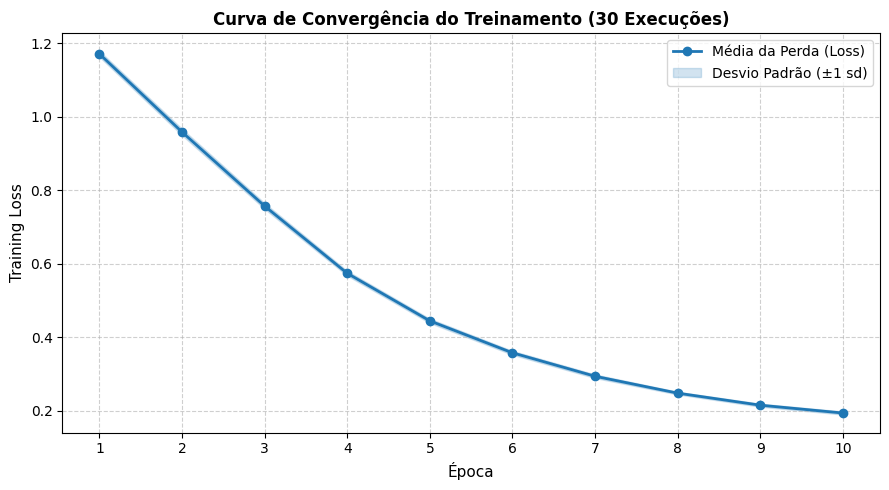


📊 RELATÓRIO ESTATÍSTICO A NÍVEL DE SPAN (30 EXPERIMENTOS)
Precision : 0.3462 (± 0.0091)
Recall    : 0.2584 (± 0.0075)
F0.5-Score: 0.3241 (± 0.0082)
Accuracy  : 0.9183 (± 0.0023)


In [12]:
# Configuração do experimento
nome_modelo = "neuralmind/bert-base-portuguese-cased"
num_experimentos = 30
num_epocas = 10
diretorio_local_temp = "/content/temp_results"

# Caminhos no Google Drive
caminho_salvamento_drive = "/content/drive/MyDrive/Colab Notebooks/resultados_bertbase_span10.csv"
caminho_losses_drive = "/content/drive/MyDrive/Colab Notebooks/losses_bertbase_span10.csv"
caminho_estatisticas_drive = "/content/drive/MyDrive/Colab Notebooks/estatisticas_bertbase_span10.csv"
caminho_grafico_loss = "/content/drive/MyDrive/Colab Notebooks/curva_loss_bertbase.png"

# Controle de Retomada das Métricas
if os.path.exists(caminho_salvamento_drive):
    print("🔄 Arquivo parcial de resultados encontrado! Carregando progresso anterior...")
    df_carregado = pd.read_csv(caminho_salvamento_drive)
    resultados_experimentos = df_carregado.to_dict(orient='records')
    rodada_inicial = len(resultados_experimentos)
    print(f"Retomando a partir da rodada {rodada_inicial + 1}...")
else:
    print('\n*** Nenhum checkpoint encontrado. Iniciando do zero... ***\n')
    resultados_experimentos = []
    rodada_inicial = 0

# Controle de Retomada das Losses (Para garantir as 30 rodadas no gráfico)
if os.path.exists(caminho_losses_drive):
    print("🔄 Arquivo parcial de losses encontrado! Carregando histórico de curvas...")
    df_losses = pd.read_csv(caminho_losses_drive)
    historico_losses_todas_rodadas = df_losses.values.tolist()
else:
    historico_losses_todas_rodadas = []

# Laço principal de experimentos
for i in range(rodada_inicial, num_experimentos):
    current_seed = 100 + i

    ds_split = full_tokenized_dataset.shuffle(seed=current_seed).train_test_split(
        test_size=0.2, seed=current_seed, keep_in_memory=True
    )

    model = AutoModelForTokenClassification.from_pretrained(
        nome_modelo,
        num_labels=len(lista_rotulos),
        id2label=id_to_label,
        label2id=label_to_id,
    ).to(device)

    output_dir_atual = os.path.join(diretorio_local_temp, f'exp_{i+1}')

    training_args = TrainingArguments(
        output_dir=output_dir_atual,
        eval_strategy='no',
        learning_rate=2e-5,
        per_device_train_batch_size=4,
        gradient_accumulation_steps=4,
        num_train_epochs=num_epocas,
        weight_decay=0.01,
        disable_tqdm=True,
        report_to=[],
        fp16=torch.cuda.is_available(),
        save_strategy='no',
        logging_strategy='epoch',
        save_total_limit=1,
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=ds_split['train'],
        data_collator=data_collator,
        compute_metrics=compute_metrics,
    )

    trainer.train()

    # Extrai estritamente a loss de treinamento registrada ao fim de cada época
    losses_rodada = [log['loss'] for log in trainer.state.log_history if 'loss' in log and 'epoch' in log][:num_epocas]
    historico_losses_todas_rodadas.append(losses_rodada)

    metrics = trainer.evaluate(eval_dataset=ds_split['test'])
    resultados_experimentos.append({
        'Precision': metrics['eval_precision'],
        'Recall': metrics['eval_recall'],
        'F0.5-Score': metrics['eval_f0_5'],
        'Accuracy': metrics['eval_accuracy'],
    })

    # Salva CSVs parciais a cada rodada finalizada (sem criar colunas extras de índice)
    df_parcial = pd.DataFrame(resultados_experimentos)
    df_parcial.to_csv(caminho_salvamento_drive, index=False)

    colunas_epocas = [f'Epoca_{e+1}' for e in range(num_epocas)]
    df_losses_parcial = pd.DataFrame(historico_losses_todas_rodadas, columns=colunas_epocas)
    df_losses_parcial.to_csv(caminho_losses_drive, index=False)

    print(f'✅ Rodada {i+1}/30 finalizada (Seed: {current_seed}) | F0_5: {metrics["eval_f0_5"]:.4f}')

    del model, trainer, ds_split
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    if os.path.exists(output_dir_atual):
        shutil.rmtree(output_dir_atual)

# Limpeza final de diretório temporário
if os.path.exists(diretorio_local_temp):
    shutil.rmtree(diretorio_local_temp)

# Estatísticas finais das métricas
df_resultados = pd.DataFrame(resultados_experimentos)
stats_media = df_resultados.mean()
stats_desvio = df_resultados.std()

df_estatisticas = pd.DataFrame({'Média': stats_media, 'Desvio_Padrão': stats_desvio})
df_estatisticas.to_csv(caminho_estatisticas_drive, index=True)

# Curva de Loss agregando as 30 rodadas salvas
if historico_losses_todas_rodadas:
    matriz_loss = np.array(historico_losses_todas_rodadas)
    media_loss_por_epoca = np.mean(matriz_loss, axis=0)
    desvio_loss_por_epoca = np.std(matriz_loss, axis=0)
    epocas = np.arange(1, len(media_loss_por_epoca) + 1)

    plt.figure(figsize=(9, 5))
    plt.plot(epocas, media_loss_por_epoca, marker='o', color='#1f77b4', linewidth=2, label='Média da Perda (Loss)')
    plt.fill_between(
        epocas,
        media_loss_por_epoca - desvio_loss_por_epoca,
        media_loss_por_epoca + desvio_loss_por_epoca,
        color='#1f77b4',
        alpha=0.2,
        label='Desvio Padrão (±1 sd)'
    )
    plt.title(f'Curva de Convergência do Treinamento ({len(historico_losses_todas_rodadas)} Execuções)', fontsize=12, fontweight='bold')
    plt.xlabel('Época', fontsize=11)
    plt.ylabel('Training Loss', fontsize=11)
    plt.xticks(epocas)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.savefig(caminho_grafico_loss, dpi=300)
    plt.show()

# Relatório final impresso no terminal
print('\n' + '=' * 45)
print(f'📊 RELATÓRIO ESTATÍSTICO A NÍVEL DE SPAN ({len(df_resultados)} EXPERIMENTOS)')
print('=' * 45)
for metrica in df_resultados.columns:
    print(f'{metrica:10}: {stats_media[metrica]:.4f} (± {stats_desvio[metrica]:.4f})')
print('=' * 45)